# Regresión Logística Ordinal con features geoespaciales

**Escenario:** geo (variables base + `distancia_*` + `cluster_zona`).

Se usa `mord.LogisticAT` con `alpha=0.1`, el mejor valor de la baseline. El pipeline escala las numéricas porque el modelo es lineal; `cluster_zona` se codifica con One-Hot.

- Entrada: `data/processed/airprice_features.csv`
- Salidas: `reports/ordinal_logistic_features_metricas.csv`, matriz de confusión e importancia por coeficientes.

In [1]:
import sys
sys.path.append('../..')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

from src.model_features import (
    PARAMS_BASE,
    construir_ordinal_features,
    evaluar_modelo_ordinal,
    importancia_variables,
    metricas_a_fila,
)
from src.model_ordinal import codificar_y, decodificar_y
from src.preprocessing_features import FEATURES_PATH, preparar_dataset_features
from src.utils import (
    CLASES,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    fijar_semilla,
    guardar_modelo,
    split_estratificado,
)

sns.set_theme(style='whitegrid')
fijar_semilla(SEED)
print('Semilla:', SEED)

Semilla: 42


In [2]:
df = preparar_dataset_features(cargar_dataset(FEATURES_PATH))
print('Filas:', df.shape[0], 'Columnas:', df.shape[1])

X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df,
    target='price_range',
    excluir=['price_clean', 'id'],
    seed=SEED,
)
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

y_train_enc = codificar_y(y_train)
y_val_enc = codificar_y(y_val)
y_test_enc = codificar_y(y_test)

Filas: 61617 Columnas: 29
Train: (43131, 28) Val: (9243, 28) Test: (9243, 28)


In [3]:
params = dict(PARAMS_BASE['ordinal_logistic'])
print('Hiperparámetros baseline:', params)

modelo = construir_ordinal_features(X_train, **params)
modelo.fit(X_train, y_train_enc)

pred_val = decodificar_y(modelo.predict(X_val))
met_val = evaluar_modelo_ordinal(y_val, pred_val)
print({k: round(v, 4) for k, v in met_val.items() if k != 'matriz_confusion'})
print('Umbrales ordinales (theta):', modelo.named_steps['modelo'].theta_)

Hiperparámetros baseline: {'alpha': 0.1}


d:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\.venv\Lib\site-packages\mord\threshold_based.py:132: OptimizeWarning: Unknown solver options: disp
  sol = optimize.minimize(obj_margin, x0, method='L-BFGS-B',


{'accuracy': 0.6305, 'balanced_accuracy': 0.6302, 'f1_macro': 0.6328, 'f1_weighted': 0.6331, 'accuracy_adjacent': 0.9681, 'mae_ordinal': 0.4053, 'qwk': 0.801}
Umbrales ordinales (theta): [-1.32843402  1.21130941  3.56512227]


{'accuracy': 0.6395, 'balanced_accuracy': 0.6393, 'f1_macro': 0.642, 'f1_weighted': 0.6422, 'accuracy_adjacent': 0.9693, 'mae_ordinal': 0.3958, 'qwk': 0.8043}


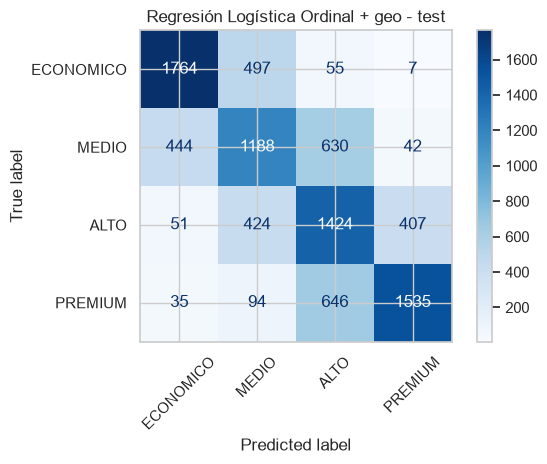

In [4]:
pred_test = decodificar_y(modelo.predict(X_test))
met_test = evaluar_modelo_ordinal(y_test, pred_test)
print({k: round(v, 4) for k, v in met_test.items() if k != 'matriz_confusion'})

ConfusionMatrixDisplay(
    met_test['matriz_confusion'], display_labels=CLASES
).plot(cmap='Blues', values_format='d')
plt.title('Regresión Logística Ordinal + geo - test')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'ordinal_logistic_features_matriz_confusion.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

                                             variable  importancia
0                            num__distancia_centro_km     3.827161
1                          cat__room_type_Shared room     2.850802
2                      cat__room_type_Entire home/apt     1.613004
3                         num__distancia_hyde_park_km     1.497673
4                       num__distancia_kings_cross_km     1.410254
5   cat__neighbourhood_cleansed_Kensington and Che...     1.203691
6    cat__neighbourhood_cleansed_Richmond upon Thames     1.094214
7                cat__neighbourhood_cleansed_Lewisham     1.090559
8                 cat__neighbourhood_cleansed_Lambeth     1.071178
9      cat__property_type_Private room in rental unit     1.069516
10                 cat__neighbourhood_cleansed_Sutton     1.062103
11            cat__property_type_Private room in home     0.979975
12         cat__neighbourhood_cleansed_City of London     0.976937
13                                  num__accommodates     0.97

C:\Users\user\AppData\Local\Temp\ipykernel_3596\3778004515.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top, x='importancia', y='variable', palette='viridis')


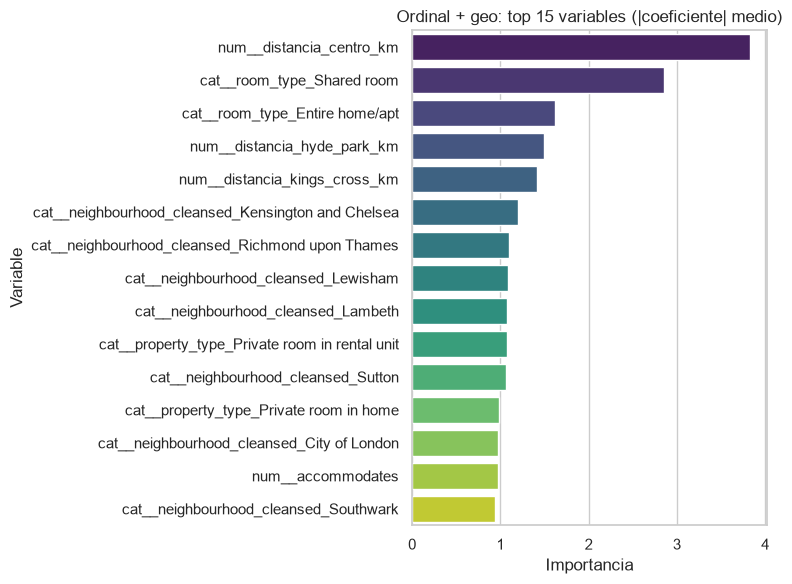

In [5]:
importancia = importancia_variables(modelo)
importancia.to_csv(
    REPORTS_DIR / 'ordinal_logistic_features_importancia.csv', index=False
)
print(importancia.head(15))

top = importancia.head(15)
plt.figure(figsize=(8, 6))
sns.barplot(data=top, x='importancia', y='variable', palette='viridis')
plt.title('Ordinal + geo: top 15 variables (|coeficiente| medio)')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'ordinal_logistic_features_importancia.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

In [6]:
fila = metricas_a_fila(
    'ordinal_logistic_features',
    met_test,
    escenario='geo',
    **params,
)
pd.DataFrame([fila]).to_csv(
    REPORTS_DIR / 'ordinal_logistic_features_metricas.csv', index=False
)

ruta = guardar_modelo(modelo, 'ordinal_logistic_features')
print('Métricas y matriz guardadas en:', REPORTS_DIR)
print('Modelo guardado en:', ruta)

Métricas y matriz guardadas en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\reports
Modelo guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\models\ordinal_logistic_features.joblib


## Lectura de resultados

- El modelo ordinal es lineal: no captura interacciones entre `accommodates`, `room_type` y ubicación. Es esperable que quede por debajo de los árboles.
- Su valor está en la estructura ordinal explícita: `mae_ordinal` y `qwk` pueden ser competitivos aunque la accuracy exacta sea menor.
- Comparar con `reports/ordinal_logistic_metricas.json`.